## MSC 7103: Machine Learning Practical Exam
### Developing and Comparing Machine Learning Models for Detecting Lean Type 2 Diabetes in Uganda: Locally Trained versus Foreign-Trained Models
**Group members:**
- Adriko Patricia Lawuri 2026/HD05/22740U 2600722740
- Kasadha Jesse 2026/HD05/22756U 2600722756

**Objective:** To develop and compare machine learning models for detecting type 2 diabetes in Ugandan adults, with a focus on **lean** adults (BMI < 25 kg/m²):
1. Which of five algorithms (Logistic Regression, Decision Tree, Random Forest, XGBoost, SVM) performs best on Ugandan data?
2. Do models trained on Ugandan data detect diabetes, especially in lean adults, better than models trained on foreign data?
3. Which features drive the predictions of foreign-trained and locally trained models?

**Datasets**
| Role | Dataset | Diabetes defined by |
|---|---|---|
| Foreign | CDC Diabetes Health Indicators, BRFSS 2015, United States (253,680 adults) | Self-report ("ever told by a doctor") |
| Local (training) | Kasujja et al. (2022): 504 outpatients at a general hospital in eastern Uganda | **Oral glucose tolerance test** (gold standard) or fasting glucose |
| Local (independent test) | WHO STEPS Survey, Uganda 2014: 3,987 adults, national | Measured fasting glucose or treatment |

**Experiments** (all evaluated on Ugandan adults, overall and for lean adults)
- **A. Foreign:** trained on US data only.
- **B. Local:** trained on Ugandan data only (five algorithms compared, including SVM).
- **C. Pre-train and fine-tune:** trained on US data, then training continued on Ugandan data.
- **D. Independent test:** all models tested on a second Ugandan population (STEPS).

### Changes from the concept paper
| Concept paper | This project | Reason |
|---|---|---|
| Mulago Hospital EHR data | Kasujja et al. (2022) open data and WHO STEPS Uganda 2014 | Hospital data was not accessible in time. Kasujja's data is open (CC BY 4.0) and confirms diabetes with the oral glucose tolerance test. The STEPS file was obtained from a public GitHub repository (Andanter, n.d.); our access request to the WHO NCD Microdata Repository (18 Nov 2026) is pending. |
| Compare with the Pima Indians dataset | Compare with US BRFSS 2015 | Pima has only 768 women, and its strongest feature (glucose) is our outcome, so a fair comparison is not possible. BRFSS shares features with both Ugandan datasets. |
| SVM chosen in advance | SVM compared with four other algorithms | Following lecturer feedback: choose the model from experiments. |
| Type 2 diabetes | Diabetes in adults (mostly type 2) | The Ugandan datasets do not record diabetes type; in Ugandan adults most diabetes is type 2. |

### 1. Setup, data loading and exploration

In [1]:
# Installing the UCI dataset library
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Importing the necessary libraries
import warnings
import numpy as np                 # numerical operations
import pandas as pd                # working with tables (dataframes)
import matplotlib.pyplot as plt    # for visualizations
import seaborn as sns              # statistical plots
import shap                        # SHAP explanations
import xgboost as xgb
from ucimlrepo import fetch_ucirepo    # downloads datasets from UCI

# Fixed random seed so results are the same every run
RANDOM_STATE = 42
sns.set_style("whitegrid")
warnings.filterwarnings("ignore")

In [3]:
# Importing the models and evaluation tools
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

#### 1.1 Foreign data: CDC Diabetes Health Indicators (BRFSS 2015, United States)

A US telephone survey (Behavioral Risk Factor Surveillance System, 2015). Diabetes is **self-reported** (told by a doctor), and prediabetes is counted as "no diabetes".

In [4]:
# Fetching the US dataset from the UCI repository (dataset id 891)
cdc_diabetes_health_indicators = fetch_ucirepo(id=891)

In [5]:
# Separating the data into features (X) and target (y)
X_us = cdc_diabetes_health_indicators.data.features
y_us = cdc_diabetes_health_indicators.data.targets

print("Features (X):", X_us.shape)
print("Target (y):", y_us.shape)

Features (X): (253680, 21)
Target (y): (253680, 1)


In [6]:
# Viewing the dataset metadata (source, purpose, sensitive attributes, etc.)
print(cdc_diabetes_health_indicators.metadata)

{'uci_id': 891, 'name': 'CDC Diabetes Health Indicators', 'repository_url': 'https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators', 'data_url': 'https://archive.ics.uci.edu/static/public/891/data.csv', 'abstract': 'The Diabetes Health Indicators Dataset contains healthcare statistics and lifestyle survey information about people in general along with their diagnosis of diabetes. The 35 features consist of some demographics, lab test results, and answers to survey questions for each patient. The target variable for classification is whether a patient has diabetes, is pre-diabetic, or healthy. ', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Tabular', 'Multivariate'], 'num_instances': 253680, 'num_features': 21, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Sex', 'Age', 'Education Level', 'Income'], 'target_col': ['Diabetes_binary'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_

In [7]:
# Viewing the variable information (what each column means)
pd.set_option("display.max_colwidth", None)    # show full descriptions
cdc_diabetes_health_indicators.variables

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,NaN,Patient ID,None,no
1,Diabetes_binary,Target,Binary,NaN,0 = no diabetes 1 = prediabetes or diabetes,None,no
2,HighBP,Feature,Binary,NaN,0 = no high BP 1 = high BP,None,no
3,HighChol,Feature,Binary,NaN,0 = no high cholesterol 1 = high cholesterol,None,no
4,CholCheck,Feature,Binary,NaN,0 = no cholesterol check in 5 years 1 = yes cholesterol check in 5 years,None,no
5,BMI,Feature,Integer,NaN,Body Mass Index,None,no
6,Smoker,Feature,Binary,NaN,Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] 0 = no 1 = yes,None,no
7,Stroke,Feature,Binary,NaN,(Ever told) you had a stroke. 0 = no 1 = yes,None,no
8,HeartDiseaseorAttack,Feature,Binary,NaN,coronary heart disease (CHD) or myocardial infarction (MI) 0 = no 1 = yes,None,no
9,PhysActivity,Feature,Binary,NaN,physical activity in past 30 days - not including job 0 = no 1 = yes,None,no


In [8]:
# Combining features and target into one table for exploration
us_raw = X_us.join(y_us)
print("Shape:", us_raw.shape)

Shape: (253680, 22)


In [9]:
# Viewing the first 5 records
us_raw.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [10]:
# Viewing the last 5 records
us_raw.tail()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
253675,1,1,1,45,0,0,0,0,1,1,...,0,3,0,5,0,1,5,6,7,0
253676,1,1,1,18,0,0,0,0,0,0,...,0,4,0,0,1,0,11,2,4,1
253677,0,0,1,28,0,0,0,1,1,0,...,0,1,0,0,0,0,2,5,2,0
253678,1,0,1,23,0,0,0,0,1,1,...,0,3,0,0,0,1,7,5,1,0
253679,1,1,1,25,0,0,1,1,1,0,...,0,2,0,0,0,0,9,6,2,1


In [11]:
# Checking the class balance (how many diabetic vs non-diabetic)
counts = us_raw["Diabetes_binary"].value_counts()
print(counts)
print("\nPercent diabetic: {:.1f}%".format(100 * counts[1] / counts.sum()))

Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Percent diabetic: 13.9%


#### 1.2 Local data (training): eastern Uganda outpatients, Kasujja et al. (2022)

Consecutive adults aged 30-75 attending the outpatient department of a general hospital in eastern Uganda. Every participant had an **oral glucose tolerance test (OGTT)**, the clinical reference test for diabetes. Open access on Figshare (CC BY 4.0, doi: 10.6084/m9.figshare.20152373).

In [12]:
# Loading the Kasujja et al. (2022) data (Stata file)
kas_raw = pd.read_stata("data/uganda_figshare/hba1c_vs_fpg_validity_data.dta", convert_categoricals=False)
print("Shape:", kas_raw.shape)

Shape: (504, 22)


In [13]:
# Viewing the variable descriptions stored in the file
with pd.read_stata("data/uganda_figshare/hba1c_vs_fpg_validity_data.dta", iterator=True) as reader:
    kas_labels = reader.variable_labels()
pd.Series(kas_labels, name="Description").to_frame()

,Description
PID,Study ID
age,Completed years
sex,Sex
education,Highest level of education
employment,Current employment
exercise,Physical activity
dysglydiag,Found to have high blood glucose
famhistdiab,family members ever been diagnosed with diabetes
height,height
weight,Weight


In [14]:
# Viewing the first 5 records
kas_raw.head()

,PID,age,sex,education,employment,exercise,dysglydiag,famhistdiab,height,weight,...,diast1,syst2,diast2,syst3,diast3,fpg,hba1c,ogtt,asymptmal,hb
0,PAR0001,50,0,1,8,1,2,2,157,71.0,...,64,98,58,93,56,6.0,48.0,10.8,1,21.6
1,PAR0002,48,0,2,8,1,2,2,159,53.0,...,119,172,105,171,116,5.5,34.0,9.7,2,12.4
2,PAR0003,69,0,2,5,1,2,2,149,149.0,...,73,136,66,129,72,0.6,33.0,8.8,2,20.9
3,PAR0004,75,1,3,8,1,2,2,173,58.0,...,71,132,75,120,74,4.8,31.0,4.4,1,14.0
4,PAR0005,58,0,2,7,1,2,2,160,61.0,...,77,123,71,111,96,4.5,42.0,5.8,1,13.6


In [15]:
# Viewing the last 5 records
kas_raw.tail()

,PID,age,sex,education,employment,exercise,dysglydiag,famhistdiab,height,weight,...,diast1,syst2,diast2,syst3,diast3,fpg,hba1c,ogtt,asymptmal,hb
499,PAR2865,45,0,1,5,1,2,2,157,84.0,...,91,126,88,128,89,12.5,69.0,18.4,1,NaN
500,PAR2866,37,0,5,3,2,2,2,161,73.0,...,70,112,68,120,80,4.7,40.0,8.7,1,NaN
501,PAR2867,35,0,4,5,1,2,2,161,52.0,...,72,108,71,104,69,6.2,36.0,8.7,1,NaN
502,PAR2868,57,1,1,8,1,2,2,162,69.0,...,74,100,75,101,78,4.6,36.0,7.4,1,NaN
503,PAR2869,64,0,2,5,1,2,2,162,91.0,...,110,146,106,149,101,7.1,55.0,12.8,1,11.0


In [16]:
# Checking column data types and missing values
kas_raw.info()
print("\nMissing values per column:")
print(kas_raw.isna().sum()[kas_raw.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 22 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PID          504 non-null    str    
 1   age          504 non-null    int8   
 2   sex          504 non-null    int8   
 3   education    504 non-null    int8   
 4   employment   504 non-null    int8   
 5   exercise     504 non-null    int8   
 6   dysglydiag   504 non-null    int8   
 7   famhistdiab  504 non-null    int8   
 8   height       504 non-null    int16  
 9   weight       504 non-null    float64
 10  waistcircum  504 non-null    float64
 11  syst1        504 non-null    int16  
 12  diast1       504 non-null    int16  
 13  syst2        504 non-null    int16  
 14  diast2       504 non-null    int16  
 15  syst3        504 non-null    int16  
 16  diast3       504 non-null    int16  
 17  fpg          504 non-null    float64
 18  hba1c        504 non-null    float64
 19  ogtt         504 no

In [17]:
# Summary statistics for the measured (numeric) columns
kas_raw[["age", "height", "weight", "waistcircum", "syst2", "diast2", "fpg", "ogtt", "hba1c"]].describe().round(1)

,age,height,weight,waistcircum,syst2,diast2,fpg,ogtt,hba1c
count,504.0,504.0,504.0,504.0,504.0,504.0,504.0,504.0,504.0
mean,47.9,161.4,68.1,89.0,131.5,85.7,5.7,8.1,41.9
std,11.3,8.0,14.8,13.7,23.5,13.5,3.0,5.6,16.3
min,30.0,138.0,39.0,37.0,51.0,53.0,0.6,2.1,20.0
25%,40.0,156.0,57.0,78.8,115.0,76.0,4.4,5.1,34.0
50%,48.0,161.0,66.0,88.0,127.0,84.0,4.8,6.3,38.0
75%,55.0,167.0,76.0,98.0,145.0,92.2,6.0,8.5,42.0
max,88.0,184.0,149.0,144.0,234.0,144.0,23.9,53.0,124.0


#### 1.3 Local data (independent test): WHO STEPS Survey, Uganda 2014

A national survey of adults aged 18-69 with measured height, weight, blood pressure and capillary fasting glucose. *Source: public GitHub repository (Andanter, n.d.); our access request to the WHO NCD Microdata Repository is pending.*

In [18]:
# Loading the WHO STEPS Uganda 2014 data (Stata file)
steps_raw = pd.read_stata("data/uganda_steps/uga2014.dta", convert_categoricals=False)
print("Shape:", steps_raw.shape)

Shape: (3987, 213)


In [19]:
# Viewing the descriptions of the columns we use (out of 213)
steps_columns = ["sex", "age", "m11", "m12", "m5a", "m5b", "m6a", "m6b", "m7",
                 "p10", "p13", "b1", "b5", "h8", "h9"]
with pd.read_stata("data/uganda_steps/uga2014.dta", iterator=True) as reader:
    steps_labels = reader.variable_labels()
pd.Series({c: steps_labels[c] for c in steps_columns}, name="Description").to_frame()

,Description
sex,sex
age,age for analysis
m11,height (cm)
m12,weight (kg)
m5a,BP reading 2: systolic
m5b,BP reading 2: diastolic
m6a,BP reading 3: systolic
m6b,BP reading 3: diastolic
m7,took raised BP meds in past 2 weeks
p10,vig leisure activity


In [ ]:
# Viewing the first 5 records (columns we use)
steps_raw[steps_columns].head()

In [ ]:
# Viewing the last 5 records (columns we use)
steps_raw[steps_columns].tail()

In [22]:
# Checking missing values in the columns we use
steps_raw[steps_columns].isna().sum().to_frame("Missing")

,Missing
sex,0
age,0
m11,297
m12,298
m5a,81
m5b,81
m6a,81
m6b,81
m7,83
p10,6


### 2. Data cleaning

- **US:** exact duplicate rows are removed, so that the same record cannot be used for both training and testing.
- **Kasujja:** some patients may have been entered twice under different study IDs.
- **STEPS:** codes 77 and 777 mean "don't know" and must not be read as glucose values.

In [23]:
# US: removing exact duplicate rows
n_before = len(us_raw)
us_raw = us_raw.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n_before:,} | duplicates removed: {n_before - len(us_raw):,} | rows after: {len(us_raw):,}")

Rows before: 253,680 | duplicates removed: 24,206 | rows after: 229,474


In [24]:
# Kasujja: checking for patients entered twice (identical measurements, different study ID)
duplicated = kas_raw.drop(columns="PID").duplicated(keep=False)
print("Records involved in duplication:", duplicated.sum())
kas_raw[duplicated].sort_values(["age", "fpg"])[["PID", "age", "sex", "height", "weight", "fpg", "ogtt"]].head(6)

Records involved in duplication: 40


,PID,age,sex,height,weight,fpg,ogtt
379,PAR0889,30,0,161,63.0,4.1,6.3
490,PAR2856,30,0,161,63.0,4.1,6.3
369,PAR0801,30,0,152,68.0,4.5,9.1
480,PAR2846,30,0,152,68.0,4.5,9.1
387,PAR0990,33,1,174,60.0,4.9,6.3
498,PAR2864,33,1,174,60.0,4.9,6.3


In [25]:
# Kasujja: removing the second copy of each duplicated patient
n_before = len(kas_raw)
kas_raw = kas_raw[~kas_raw.drop(columns="PID").duplicated()].reset_index(drop=True)
print(f"Patients before: {n_before} | duplicates removed: {n_before - len(kas_raw)} | patients after: {len(kas_raw)}")

Patients before: 504 | duplicates removed: 20 | patients after: 484


In [26]:
# STEPS: checking the glucose column for "don't know" codes (77 / 777) and impossible values
print(steps_raw["b5"].describe().round(2))
print("\nValues of 30 mmol/L or more:", sorted(steps_raw.loc[steps_raw["b5"] >= 30, "b5"].unique()))

count    3691.00
mean        4.34
std        18.03
min         1.10
25%         3.20
50%         3.80
75%         4.50
max       777.00
Name: b5, dtype: float64

Values of 30 mmol/L or more: [np.float64(777.0)]


### 3. Data preparation: shared features and outcome

A model can only be tested on Ugandans if the datasets have **the same features with the same meaning**. Five features are available in all three:

| Feature | US (BRFSS) | Uganda outpatients (Kasujja) | Uganda national (STEPS) |
|---|---|---|---|
| Age | 13 age bands (18-24 ... 80+) | Age in years, converted to the same bands | Age in years, converted to the same bands |
| Sex | 1 = male | 1 = male | `sex` |
| BMI | Self-reported height and weight | **Measured** | **Measured** |
| HighBP | Ever told by a doctor | **Measured** ≥ 140/90 mmHg | **Measured** ≥ 140/90 mmHg or on treatment |
| PhysActivity | Any exercise in past 30 days | Physically active (yes/no) | Moderate or vigorous leisure activity |

**Outcome:** US = self-reported diabetes. Kasujja = 2-hour OGTT glucose ≥ 11.1 mmol/L or fasting plasma glucose ≥ 7.0 mmol/L (WHO criteria). STEPS = fasting glucose ≥ 7.0 mmol/L or on treatment for raised glucose.

In [27]:
# Helper functions: BMI groups (lean < 25) and the 13 US age bands (1 = 18-24, ..., 13 = 80+)
def bmi_group(bmi):
    return pd.cut(bmi, bins=[0, 25, 30, 200], right=False,
                  labels=["Lean (<25)", "Overweight (25-29.9)", "Obese (30+)"])

def age_band(age_years):
    bins = [17, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74, 79, 120]
    return pd.cut(age_years, bins=bins, labels=range(1, 14)).astype(float)

In [28]:
# US: keeping the five shared features and the outcome
shared_features = ["Age", "Sex", "BMI", "HighBP", "PhysActivity"]
us = us_raw.rename(columns={"Diabetes_binary": "Diabetes"})[shared_features + ["Diabetes"]]
print("US adults:", len(us), "| diabetes rate:", round(us["Diabetes"].mean(), 3))

US adults: 229474 | diabetes rate: 0.153


In [29]:
# Kasujja: building the features and the outcome (codes: 1 = Yes, 2 = No)
def prepare_kasujja(raw):
    sbp = raw[["syst2", "syst3"]].mean(axis=1)        # average of readings 2 and 3 (WHO STEPS practice)
    dbp = raw[["diast2", "diast3"]].mean(axis=1)
    df = pd.DataFrame({
        "Age": age_band(raw["age"]), "Sex": raw["sex"],  # 1 = male
        "BMI": raw["weight"] / (raw["height"] / 100) ** 2,
        "HighBP": ((sbp >= 140) | (dbp >= 90)).astype(int),
        "PhysActivity": (raw["exercise"] == 1).astype(int),
        "AgeYears": raw["age"], "Waist": raw["waistcircum"], "SBP": sbp, "DBP": dbp,
        "FamilyHistory": (raw["famhistdiab"] == 1).astype(int)})
    df["Diabetes"] = ((raw["ogtt"] >= 11.1) | (raw["fpg"] >= 7.0)).astype(int)
    return df

kas = prepare_kasujja(kas_raw)
local_features = ["AgeYears", "Sex", "BMI", "Waist", "SBP", "DBP", "FamilyHistory", "PhysActivity"]
kas.head()

,Age,Sex,BMI,HighBP,PhysActivity,AgeYears,Waist,SBP,DBP,FamilyHistory,Diabetes
0,7.0,0,28.804414,0,1,50,110.0,95.5,57.0,0,0
1,6.0,0,20.964361,1,1,48,88.0,171.5,110.5,0,0
2,10.0,0,67.114094,0,1,69,87.0,132.5,69.0,0,0
3,12.0,1,19.379197,0,1,75,79.0,126.0,74.5,0,0
4,8.0,0,23.828125,0,1,58,84.0,117.0,83.5,0,0


In [30]:
# STEPS: building the shared features and the outcome (codes: 1 = Yes, 2 = No; 77/777 = don't know)
def prepare_steps(raw):
    sbp = raw[["m5a", "m6a"]].mean(axis=1)            # average of readings 2 and 3
    dbp = raw[["m5b", "m6b"]].mean(axis=1)
    glucose = raw["b5"].where(raw["b5"] < 77)
    on_glucose_treatment = (raw["h8"] == 1) | (raw["h9"] == 1)
    df = pd.DataFrame({
        "Age": age_band(raw["age"]), "Sex": (raw["sex"] == "Men").astype(int),
        "BMI": raw["m12"] / (raw["m11"] / 100) ** 2,
        "HighBP": ((sbp >= 140) | (dbp >= 90) | (raw["m7"] == 1)).astype(int),
        "PhysActivity": ((raw["p10"] == 1) | (raw["p13"] == 1)).astype(int)})
    df["Diabetes"] = ((glucose >= 7.0) | on_glucose_treatment).astype(int)
    keep = (glucose.notna() | on_glucose_treatment) & df["BMI"].between(12, 70)
    return df[keep].reset_index(drop=True)

steps = prepare_steps(steps_raw)
print("Adults with a glucose result and a valid BMI:", len(steps))

Adults with a glucose result and a valid BMI: 3410


In [31]:
# Checking the class balance in each dataset
datasets = {"US (BRFSS)": us, "Uganda outpatients (Kasujja)": kas, "Uganda national (STEPS)": steps}
balance = pd.DataFrame({name: {"People": len(df), "Diabetic": df["Diabetes"].sum(),
                               "% diabetic": round(100 * df["Diabetes"].mean(), 1)}
                        for name, df in datasets.items()}).T
balance

,People,Diabetic,% diabetic
US (BRFSS),229474.0,35097.0,15.3
Uganda outpatients (Kasujja),484.0,82.0,16.9
Uganda national (STEPS),3410.0,44.0,1.3


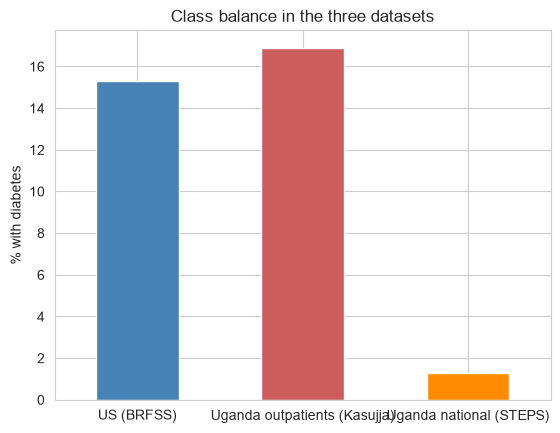

In [32]:
# Bar chart of the percentage diabetic in each dataset
balance["% diabetic"].plot(kind="bar", color=["steelblue", "indianred", "darkorange"])
plt.ylabel("% with diabetes")
plt.title("Class balance in the three datasets")
plt.xticks(rotation=0)
plt.show()

### 4. Exploratory data analysis

We first explore the Ugandan outpatients (the training data), then compare the three populations, focusing on **how many diabetics are lean**.

In [33]:
# Kasujja: average of each feature for people with and without diabetes
kas.groupby("Diabetes")[local_features].mean().T.round(2).rename(columns={0: "No diabetes", 1: "Diabetes"})

Diabetes,No diabetes,Diabetes
AgeYears,47.20,51.79
Sex,0.20,0.27
BMI,25.68,28.39
Waist,87.69,95.04
SBP,128.66,139.04
DBP,84.21,90.18
FamilyHistory,0.17,0.27
PhysActivity,0.97,0.95


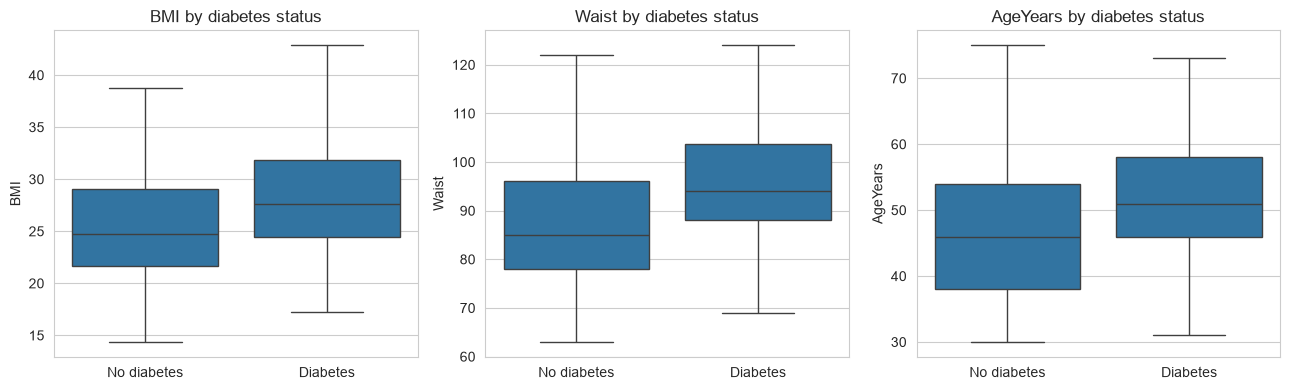

In [34]:
# Kasujja: comparing BMI, waist and age between diabetic and non-diabetic patients
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["BMI", "Waist", "AgeYears"]):
    sns.boxplot(data=kas, x="Diabetes", y=col, ax=ax, showfliers=False)
    ax.set_xticks([0, 1], ["No diabetes", "Diabetes"])
    ax.set_xlabel("")
    ax.set_title(f"{col} by diabetes status")
plt.tight_layout()
plt.show()

In [35]:
# Helper function: plots the % with diabetes in each category of a column (Kasujja)
def plot_diabetes_rate(df, groups, title, ax):
    rate = df.groupby(groups, observed=True)["Diabetes"].mean() * 100
    rate.plot(kind="bar", color="indianred", ax=ax)
    ax.set_ylabel("% with diabetes")
    ax.set_xlabel("")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)

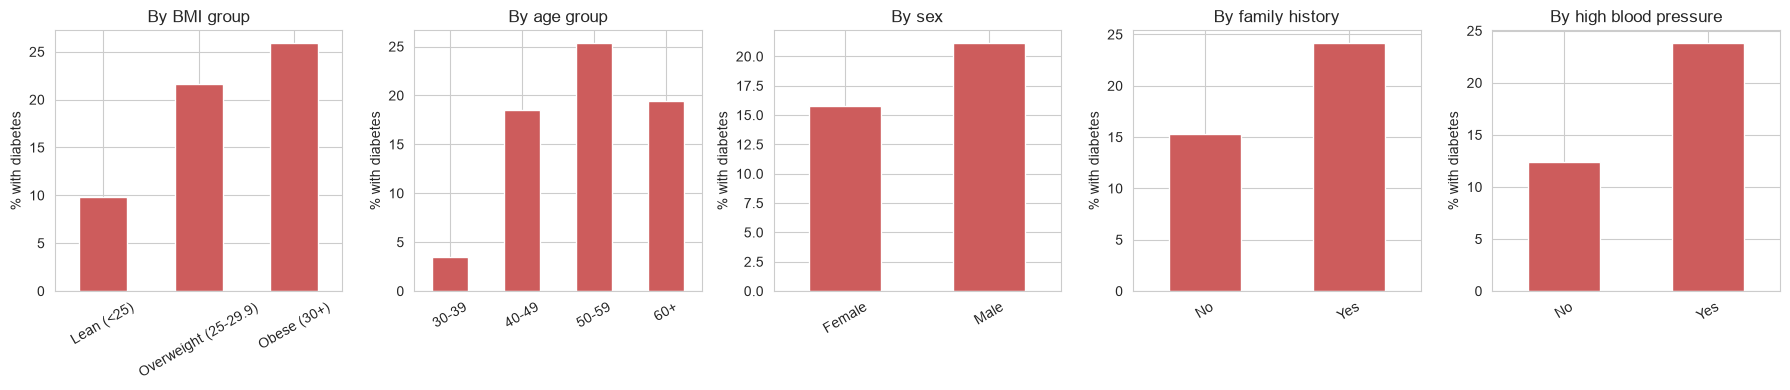

In [36]:
# Kasujja: diabetes rate by BMI group, age group, sex, family history and blood pressure
age_group = pd.cut(kas["AgeYears"], bins=[29, 39, 49, 59, 120], labels=["30-39", "40-49", "50-59", "60+"])
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
plot_diabetes_rate(kas, bmi_group(kas["BMI"]), "By BMI group", axes[0])
plot_diabetes_rate(kas, age_group, "By age group", axes[1])
plot_diabetes_rate(kas, kas["Sex"].map({0: "Female", 1: "Male"}), "By sex", axes[2])
plot_diabetes_rate(kas, kas["FamilyHistory"].map({0: "No", 1: "Yes"}), "By family history", axes[3])
plot_diabetes_rate(kas, kas["HighBP"].map({0: "No", 1: "Yes"}), "By high blood pressure", axes[4])
plt.tight_layout()
plt.show()

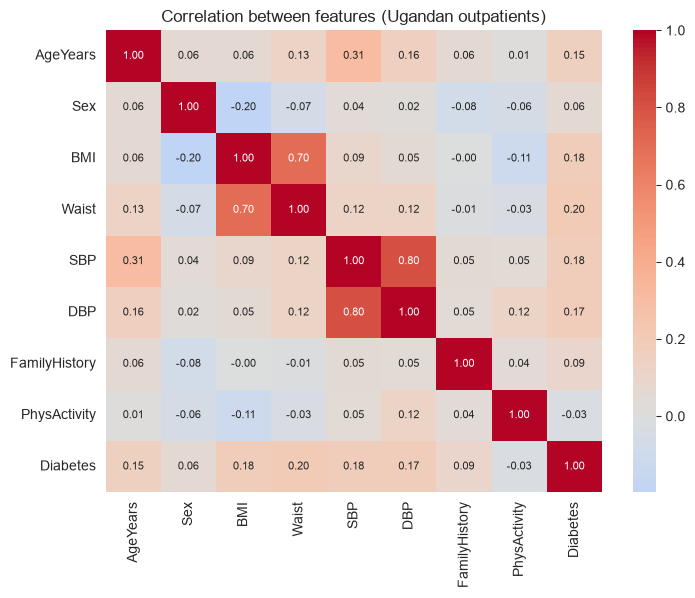

In [37]:
# Kasujja: correlation between features and with diabetes
plt.figure(figsize=(8, 6))
sns.heatmap(kas[local_features + ["Diabetes"]].corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Correlation between features (Ugandan outpatients)")
plt.show()

In [38]:
# Comparing the three populations: how common is diabetes, and how many diabetics are lean?
def describe(df):
    diabetics = df[df["Diabetes"] == 1]
    return {"People": len(df), "Diabetics": len(diabetics), "Diabetes rate": df["Diabetes"].mean(),
            "Male": df["Sex"].mean(), "Mean BMI": df["BMI"].mean(),
            "Lean (BMI < 25)": (df["BMI"] < 25).mean(),
            "Lean among diabetics": (diabetics["BMI"] < 25).mean()}

pd.DataFrame({name: describe(df) for name, df in datasets.items()}).round(3)

,US (BRFSS),Uganda outpatients (Kasujja),Uganda national (STEPS)
People,229474.000,484.000,3410.000
Diabetics,35097.000,82.000,44.000
Diabetes rate,0.153,0.169,0.013
Male,0.439,0.215,0.419
Mean BMI,28.688,26.136,22.882
Lean (BMI < 25),0.270,0.481,0.780
Lean among diabetics,0.116,0.280,0.614


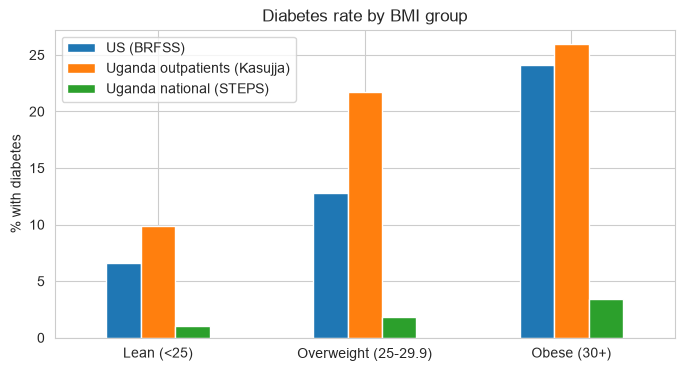

In [39]:
# Diabetes rate by BMI group in each dataset
rates = pd.DataFrame({name: df.groupby(bmi_group(df["BMI"]), observed=True)["Diabetes"].mean() * 100
                      for name, df in datasets.items()})
rates.plot(kind="bar", figsize=(8, 4), rot=0)
plt.ylabel("% with diabetes")
plt.xlabel("")
plt.title("Diabetes rate by BMI group")
plt.show()

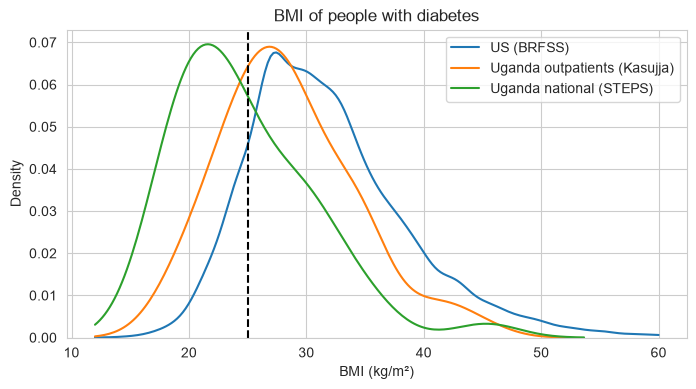

In [40]:
# BMI of people WITH diabetes in each dataset (dashed line = lean cut-off of 25)
plt.figure(figsize=(8, 4))
for name, df in datasets.items():
    sns.kdeplot(df.loc[df["Diabetes"] == 1, "BMI"], label=name, common_norm=False, clip=(12, 60))
plt.axvline(25, color="black", linestyle="--")
plt.xlabel("BMI (kg/m²)")
plt.title("BMI of people with diabetes")
plt.legend()
plt.show()

In [41]:
# Share of diabetics in each BMI group (who would an obesity-focused screen miss?)
share = pd.DataFrame({name: bmi_group(df.loc[df["Diabetes"] == 1, "BMI"]).value_counts(normalize=True)
                      for name, df in datasets.items()})
share.round(3)

,US (BRFSS),Uganda outpatients (Kasujja),Uganda national (STEPS)
BMI,,,
Lean (<25),0.116,0.280,0.614
Overweight (25-29.9),0.301,0.378,0.227
Obese (30+),0.583,0.341,0.159


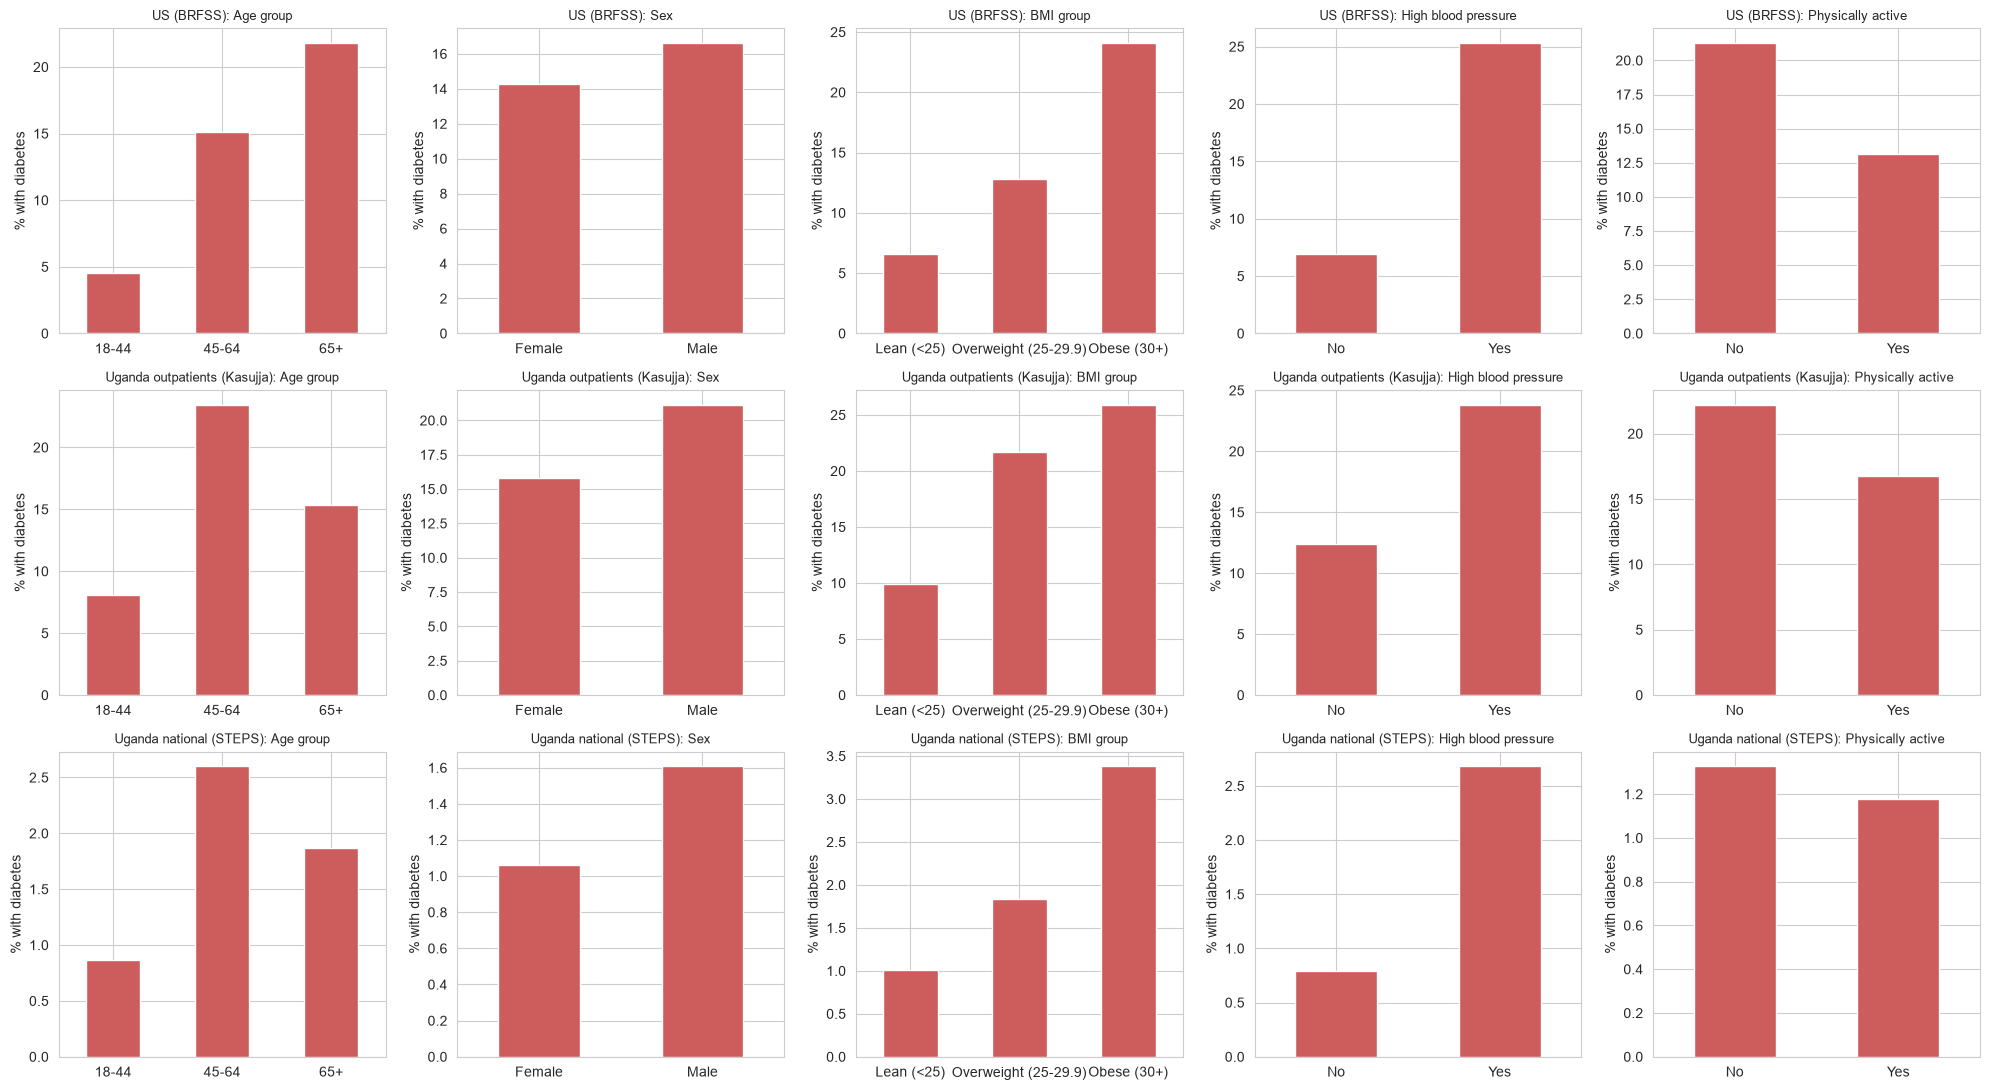

In [42]:
# Diabetes rate by each of the five shared features, in each dataset (one row per dataset)
by = {"Age group": lambda df: pd.cut(df["Age"], bins=[0, 5, 9, 13], labels=["18-44", "45-64", "65+"]),
      "Sex": lambda df: df["Sex"].map({0: "Female", 1: "Male"}),
      "BMI group": lambda df: bmi_group(df["BMI"]),
      "High blood pressure": lambda df: df["HighBP"].map({0: "No", 1: "Yes"}),
      "Physically active": lambda df: df["PhysActivity"].map({0: "No", 1: "Yes"})}
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for row, (name, df) in enumerate(datasets.items()):
    for col, (title, grouping) in enumerate(by.items()):
        ax = axes[row, col]
        (df.groupby(grouping(df), observed=True)["Diabetes"].mean() * 100).plot(
            kind="bar", ax=ax, rot=0, color="indianred")
        ax.set_title(f"{name}: {title}", fontsize=9)
        ax.set_xlabel("")
        ax.set_ylabel("% with diabetes")
plt.tight_layout()
plt.show()

#### Key EDA observations

1. **Lean diabetes is common in Uganda but rare in the US:** only **12%** of US diabetics are lean, compared with **28%** of the Ugandan outpatients with diabetes and **61%** of diabetics in the national STEPS survey. Most US diabetics (58%) are obese.
2. **BMI separates diabetics less clearly in Uganda:** among the outpatients, diabetes rises from 9.9% in lean patients to 25.9% in obese patients. Many diabetics have a BMI in the normal range, so a model that relies mainly on BMI will miss them.
3. **Ugandan diabetics are older and have higher blood pressure and waist size:** on average 51.8 vs 47.2 years, systolic blood pressure 139 vs 129 mmHg, and waist 95 vs 88 cm.
4. **Class imbalance differs:** 15.3% diabetic in the US data, 16.9% in the outpatients, but only 1.3% in the national survey. We therefore use AUC, sensitivity, specificity, precision and F1 rather than accuracy.
5. **Sex imbalance in the outpatient data:** only 21.5% of the outpatients are men (42% in the national survey). This may reflect lower use of health facilities and screening by Ugandan men, so results for men are less certain.
6. **Data quality:** 20 outpatients were recorded twice under different study IDs and were removed. The STEPS glucose column uses 777 for "don't know", which was set to missing.
7. **Different definitions:** diabetes is self-reported in the US data, but measured in both Ugandan datasets (OGTT in the outpatients). High blood pressure is self-reported in the US data but measured in Uganda.

### 5. Evaluation design

- **Repeated stratified cross-validation** on the Kasujja data (5 folds, repeated 10 times), because 484 patients is too few for a single test split. 
- **Class weights** counter the imbalance (17% diabetic).
- **Metrics:** AUC, sensitivity, specificity, precision and F1, reported **overall, for lean and non-lean adults, and for women and men**, as the mean across the 10 repeats with the 95% range.

In [43]:
# Choosing the highest threshold that catches at least 80% of diabetics
def choose_threshold(y_true, probs, target=0.80):
    y_true = np.asarray(y_true)
    for t in np.arange(0.99, 0.0, -0.01):
        if ((probs >= t) & (y_true == 1)).sum() / (y_true == 1).sum() >= target:
            return round(t, 2)
    return 0.0

In [44]:
# Scoring one set of predictions: AUC, sensitivity, specificity, precision and F1
def score(y_true, probs, preds):
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y_true, probs), "Sensitivity": tp / (tp + fn),
            "Specificity": tn / (tn + fp), "Precision": tp / max(tp + fp, 1),
            "F1": 2 * tp / max(2 * tp + fp + fn, 1)}

In [45]:
# Repeated 5-fold cross-validation: out-of-fold risks and screening decisions for every patient
def repeated_cv(model, X, y, n_repeats=10):
    results = []
    for repeat in range(n_repeats):
        folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=repeat)
        probs, preds = np.zeros(len(y)), np.zeros(len(y), dtype=int)
        for train, test in folds.split(X, y):
            fitted = clone(model).fit(X.iloc[train], y.iloc[train])
            inner = cross_val_predict(clone(model), X.iloc[train], y.iloc[train], cv=3,
                                      method="predict_proba")[:, 1]
            threshold = choose_threshold(y.iloc[train], inner)
            probs[test] = fitted.predict_proba(X.iloc[test])[:, 1]
            preds[test] = probs[test] >= threshold
        results.append((probs, preds))
    return results

In [46]:
# Summarising results by patient group: mean across repeats, with the 95% range for AUC and sensitivity
def summarise(results, df):
    y = df["Diabetes"].to_numpy()
    groups = {"All": np.ones(len(df), bool), "Lean (<25)": (df["BMI"] < 25).to_numpy(),
              "Not lean (25+)": (df["BMI"] >= 25).to_numpy(),
              "Women": (df["Sex"] == 0).to_numpy(), "Men": (df["Sex"] == 1).to_numpy()}
    rows = []
    for group, mask in groups.items():
        s = pd.DataFrame([score(y[mask], p[mask], d[mask]) for p, d in results])
        row = {"Group": group, "People": mask.sum(), "Diabetics": y[mask].sum(),
               "Diabetics caught": f"{s['Sensitivity'].mean() * y[mask].sum():.0f} of {y[mask].sum()}",
               **s.mean().to_dict()}
        row["AUC 95% range"] = f"{s['AUC'].quantile(.025):.2f}-{s['AUC'].quantile(.975):.2f}"
        row["Sens. 95% range"] = f"{s['Sensitivity'].quantile(.025):.2f}-{s['Sensitivity'].quantile(.975):.2f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("Group").round(3)

### 6. Experiment A: foreign model (trained on US data)

An XGBoost model is trained on US adults using the five shared features. 

In [47]:
# Training XGBoost on the US data, with a threshold chosen on a US hold-out set
X_us_train, X_us_hold, y_us_train, y_us_hold = train_test_split(
    us[shared_features], us["Diabetes"], test_size=0.2, stratify=us["Diabetes"], random_state=RANDOM_STATE)
us_weight = (y_us_train == 0).sum() / y_us_train.sum()
us_model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, scale_pos_weight=us_weight,
                         eval_metric="logloss", random_state=RANDOM_STATE).fit(X_us_train, y_us_train)
us_hold_probs = us_model.predict_proba(X_us_hold)[:, 1]
us_threshold = choose_threshold(y_us_hold, us_hold_probs)
print(f"US hold-out AUC: {roc_auc_score(y_us_hold, us_hold_probs):.3f} | threshold: {us_threshold}")

US hold-out AUC: 0.771 | threshold: 0.46


In [48]:
# Applying the US model, unchanged, to the Ugandan outpatients(Kasujja dataset) this simulates what happens if a clinic in Uganda simply downloads a foreign diabetes tool and uses it.
kas_probs_us = us_model.predict_proba(kas[shared_features])[:, 1]
results_A = [(kas_probs_us, (kas_probs_us >= us_threshold).astype(int))]
summary_A = summarise(results_A, kas)
summary_A

,People,Diabetics,Diabetics caught,AUC,Sensitivity,Specificity,Precision,F1,AUC 95% range,Sens. 95% range
Group,,,,,,,,,,
All,484,82,31 of 82,0.689,0.378,0.853,0.344,0.360,0.69-0.69,0.38-0.38
Lean (<25),233,23,2 of 23,0.646,0.087,0.976,0.286,0.133,0.65-0.65,0.09-0.09
Not lean (25+),251,59,29 of 59,0.645,0.492,0.719,0.349,0.408,0.64-0.64,0.49-0.49
Women,380,60,20 of 60,0.667,0.333,0.844,0.286,0.308,0.67-0.67,0.33-0.33
Men,104,22,11 of 22,0.750,0.500,0.890,0.550,0.524,0.75-0.75,0.50-0.50


#### A fairer test: the US model with a threshold chosen on Ugandan data

Screening threshold is chosen on Ugandan training folds, with the same cross-validation as the local models.

In [49]:
# A wrapper that keeps a trained XGBoost model frozen: "fitting" it on Ugandan data changes nothing
class FrozenXGB(ClassifierMixin, BaseEstimator):
    def __init__(self, booster=None):
        self.booster = booster

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = self.booster.predict(xgb.DMatrix(X))
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [50]:
# Cross-validating the frozen US model, with thresholds chosen on Ugandan training folds
results_A2 = repeated_cv(FrozenXGB(booster=us_model.get_booster()), kas[shared_features], kas["Diabetes"])
summary_A2 = summarise(results_A2, kas)
summary_A2

,People,Diabetics,Diabetics caught,AUC,Sensitivity,Specificity,Precision,F1,AUC 95% range,Sens. 95% range
Group,,,,,,,,,,
All,484,82,65 of 82,0.689,0.796,0.485,0.240,0.369,0.69-0.69,0.77-0.81
Lean (<25),233,23,13 of 23,0.646,0.565,0.633,0.144,0.230,0.65-0.65,0.57-0.57
Not lean (25+),251,59,52 of 59,0.645,0.886,0.323,0.287,0.434,0.64-0.64,0.85-0.91
Women,380,60,48 of 60,0.667,0.800,0.476,0.223,0.348,0.67-0.67,0.77-0.82
Men,104,22,17 of 22,0.750,0.786,0.521,0.306,0.440,0.75-0.75,0.77-0.82


### 7. Experiment B: local models (trained on Ugandan data)

Five algorithms are compared on the Kasujja data with the **same five shared features**, so the comparison with the US model is fair. Logistic Regression is the interpretable baseline. Hyperparameters are kept simple and conservative because the dataset is small.

In [51]:
# Defining the five algorithms (class weights counter the 17% diabetes rate)
kas_weight = (kas["Diabetes"] == 0).sum() / kas["Diabetes"].sum()
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced",
                                            random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, scale_pos_weight=kas_weight,
                             eval_metric="logloss", random_state=RANDOM_STATE),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", probability=True,
                                                     random_state=RANDOM_STATE))}

In [52]:
# Running repeated cross-validation for each algorithm on the shared features (takes a few minutes)
results_B = {name: repeated_cv(model, kas[shared_features], kas["Diabetes"]) for name, model in models.items()}

In [53]:
# Comparing the five algorithms: all patients and lean patients
comparison = pd.concat({name: summarise(res, kas).loc[["All", "Lean (<25)"]]
                        for name, res in results_B.items()})
comparison[["Diabetics caught", "AUC", "AUC 95% range", "Sensitivity", "Specificity", "Precision", "F1"]]

Diabetics caught    AUC AUC 95% range  \
                    Group                                              
Logistic Regression All                69 of 82  0.668     0.66-0.68   
                    Lean (<25)         15 of 23  0.611     0.60-0.62   
Decision Tree       All                69 of 82  0.637     0.61-0.66   
                    Lean (<25)         14 of 23  0.538     0.47-0.59   
Random Forest       All                67 of 82  0.661     0.65-0.68   
                    Lean (<25)         11 of 23  0.553     0.51-0.59   
XGBoost             All                71 of 82  0.641     0.62-0.65   
                    Lean (<25)         15 of 23  0.550     0.51-0.58   
SVM (RBF)           All                69 of 82  0.641     0.61-0.66   
                    Lean (<25)         14 of 23  0.578     0.55-0.63   

                                Sensitivity  Specificity  Precision     F1  
                    Group                                                   
Logistic Regression All               0.843        0.366      0.213  0.341  
                    Lean (<25)        0.635        0.532      0.129  0.215  
Decision Tree       All               0.839        0.355      0.210  0.335  
                    Lean (<25)        0.609        0.465      0.111  0.187  
Random Forest       All               0.812        0.427      0.224  0.351  
                    Lean (<25)        0.487        0.570      0.111  0.180  
XGBoost             All               0.865        0.350      0.213  0.342  
                    Lean (<25)        0.648        0.447      0.114  0.193  
SVM (RBF)           All               0.837        0.341      0.206  0.330  
                    Lean (<25)        0.617        0.486      0.117  0.196

In [54]:
# Choosing the best local algorithm by overall AUC
overall_auc = comparison.xs("All", level=1)["AUC"].sort_values(ascending=False)
best_name = overall_auc.index[0]
print(overall_auc.round(3))
print("\nBest local algorithm:", best_name)

Logistic Regression    0.668
Random Forest          0.661
XGBoost                0.641
SVM (RBF)              0.641
Decision Tree          0.637
Name: AUC, dtype: float64

Best local algorithm: Logistic Regression


In [55]:
# Model performance: AUC of the five algorithms with bootstrap 95% confidence intervals
# (out-of-fold risks averaged over the 10 repeats; 1,000 bootstrap resamples of the patients)
rng = np.random.default_rng(RANDOM_STATE)
y_kas = kas["Diabetes"].to_numpy()
samples = [rng.integers(0, len(y_kas), len(y_kas)) for _ in range(1000)]
auc_table = {}
for name, res in results_B.items():
    risk = np.mean([probs for probs, preds in res], axis=0)
    boots = [roc_auc_score(y_kas[s], risk[s]) for s in samples]
    auc_table[name] = {"AUC": roc_auc_score(y_kas, risk),
                       "95% CI low": np.percentile(boots, 2.5), "95% CI high": np.percentile(boots, 97.5)}
auc_table = pd.DataFrame(auc_table).T.sort_values("AUC", ascending=False)
auc_table.round(3)

,AUC,95% CI low,95% CI high
Logistic Regression,0.671,0.606,0.738
Random Forest,0.663,0.600,0.726
XGBoost,0.649,0.586,0.711
SVM (RBF),0.648,0.580,0.712
Decision Tree,0.639,0.573,0.700


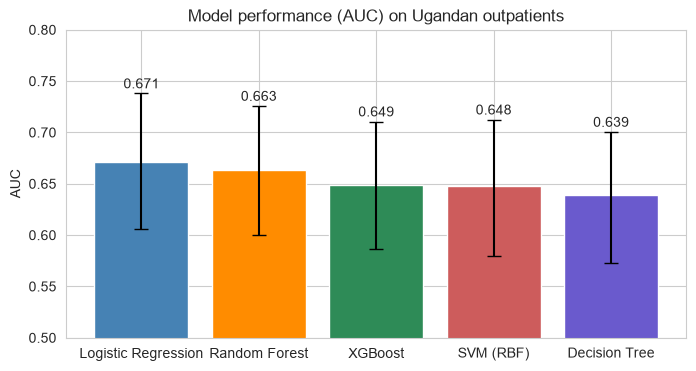

In [56]:
# Model performance chart (error bars = bootstrap 95% confidence intervals)
errors = [auc_table["AUC"] - auc_table["95% CI low"], auc_table["95% CI high"] - auc_table["AUC"]]
plt.figure(figsize=(8, 4))
plt.bar(auc_table.index, auc_table["AUC"], yerr=errors, capsize=5,
        color=["steelblue", "darkorange", "seagreen", "indianred", "slateblue"])
for i, (v, high) in enumerate(zip(auc_table["AUC"], auc_table["95% CI high"])):
    plt.text(i, high + 0.005, f"{v:.3f}", ha="center")
plt.ylim(0.5, 0.8)
plt.ylabel("AUC")
plt.title("Model performance (AUC) on Ugandan outpatients")
plt.show()

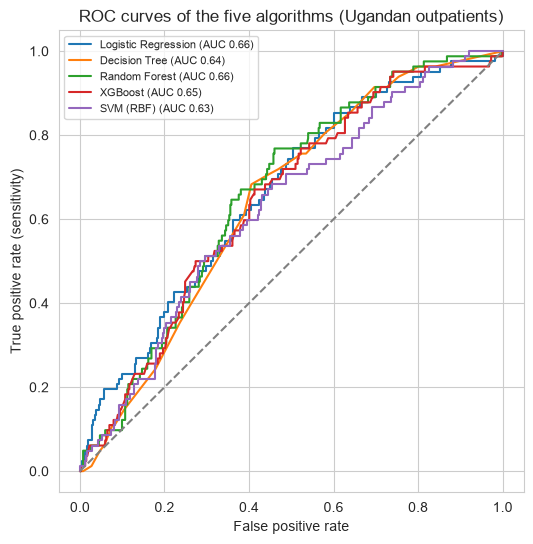

In [57]:
# ROC curves of the five algorithms (first cross-validation repeat, all patients)
plt.figure(figsize=(6, 6))
for name, res in results_B.items():
    fpr, tpr, _ = roc_curve(kas["Diabetes"], res[0][0])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(kas['Diabetes'], res[0][0]):.2f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curves of the five algorithms (Ugandan outpatients)")
plt.legend(fontsize=8)
plt.show()

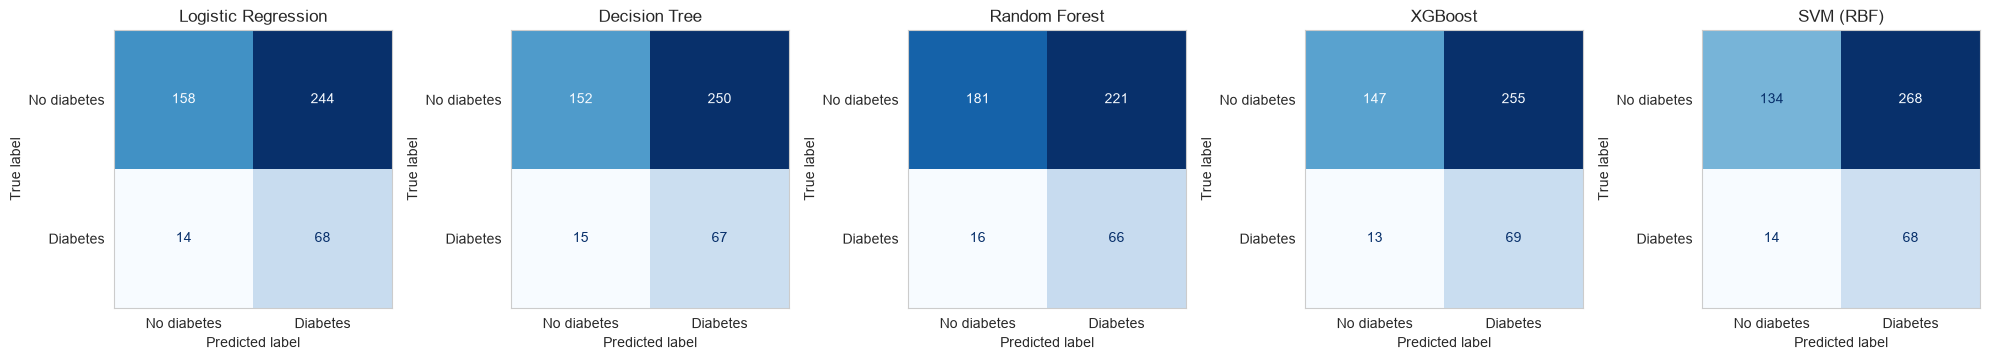

In [58]:
# Confusion matrices of the five algorithms (first cross-validation repeat, all patients)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (name, res) in zip(axes, results_B.items()):
    ConfusionMatrixDisplay.from_predictions(kas["Diabetes"], res[0][1], ax=ax, cmap="Blues", colorbar=False,
                                            display_labels=["No diabetes", "Diabetes"])
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

In [59]:
# Does the best local model gain from Ugandan-only features (waist, measured blood pressure, family history)?
results_B_full = repeated_cv(models[best_name], kas[local_features], kas["Diabetes"])
summary_B_full = summarise(results_B_full, kas)
summary_B_full

,People,Diabetics,Diabetics caught,AUC,Sensitivity,Specificity,Precision,F1,AUC 95% range,Sens. 95% range
Group,,,,,,,,,,
All,484,82,75 of 82,0.682,0.915,0.264,0.202,0.331,0.67-0.69,0.85-0.95
Lean (<25),233,23,17 of 23,0.602,0.757,0.411,0.123,0.212,0.55-0.63,0.61-0.87
Not lean (25+),251,59,58 of 59,0.656,0.976,0.103,0.251,0.399,0.64-0.66,0.95-1.00
Women,380,60,54 of 60,0.650,0.900,0.279,0.190,0.313,0.63-0.66,0.85-0.93
Men,104,22,21 of 22,0.772,0.955,0.205,0.244,0.388,0.74-0.80,0.86-1.00


#### Interpreting the Logistic Regression: odds ratios

An **odds ratio (OR)** shows how much a feature multiplies the odds of diabetes:
- **OR = 1:** no effect.
- **OR above 1:** raises the odds. 1.29 means 29% higher odds; 2.0 means double.
- **OR below 1:** lowers the odds. 0.62 means 38% lower odds.

If the 95% confidence interval includes 1, the effect is not statistically clear. Continuous features are expressed in clinically meaningful steps (for example, per 10 years of age).

In [60]:
# Odds ratios from Logistic Regression with all local features (bootstrap 95% confidence intervals)
per = {"AgeYears": 10, "Sex": 1, "BMI": 5, "Waist": 10, "SBP": 10, "DBP": 10, "FamilyHistory": 1, "PhysActivity": 1}
labels = {"AgeYears": "per 10 years", "Sex": "male vs female", "BMI": "per 5 kg/m²", "Waist": "per 10 cm",
          "SBP": "per 10 mmHg", "DBP": "per 10 mmHg", "FamilyHistory": "yes vs no", "PhysActivity": "yes vs no"}
X_steps = kas[local_features] / pd.Series(per)            # e.g. age measured in 10-year steps
fit_coefs = lambda X, y: LogisticRegression(penalty=None, max_iter=5000).fit(X, y).coef_[0]
rng = np.random.default_rng(RANDOM_STATE)
boot = np.array([fit_coefs(X_steps.iloc[s], y_kas[s])
                 for s in (rng.integers(0, len(y_kas), len(y_kas)) for _ in range(1000))])
odds_ratios = pd.DataFrame({"Unit": labels, "Odds ratio": np.exp(fit_coefs(X_steps, y_kas)),
                            "95% CI low": np.exp(np.percentile(boot, 2.5, axis=0)),
                            "95% CI high": np.exp(np.percentile(boot, 97.5, axis=0))}, index=local_features)
odds_ratios.round(2)

,Unit,Odds ratio,95% CI low,95% CI high
AgeYears,per 10 years,1.29,1.02,1.65
Sex,male vs female,1.72,0.91,3.19
BMI,per 5 kg/m²,1.25,0.96,1.87
Waist,per 10 cm,1.25,0.97,1.63
SBP,per 10 mmHg,1.04,0.83,1.32
DBP,per 10 mmHg,1.26,0.87,1.80
FamilyHistory,yes vs no,1.86,0.99,3.34
PhysActivity,yes vs no,0.62,0.23,4.91


### 8. Experiment C: pre-train on US data, fine-tune on Ugandan data

 Here the US model's 300 trees are kept, and **100 more trees are added that are trained only on Ugandan data**

In [61]:
# A model that continues training the US XGBoost model on Ugandan data
class FineTunedXGB(ClassifierMixin, BaseEstimator):
    def __init__(self, pretrained_booster=None, extra_trees=100):
        self.pretrained_booster = pretrained_booster
        self.extra_trees = extra_trees

    def fit(self, X, y):
        weight = (y == 0).sum() / y.sum()
        self.model_ = XGBClassifier(n_estimators=self.extra_trees, max_depth=2, learning_rate=0.05,
                                    scale_pos_weight=weight, eval_metric="logloss", random_state=RANDOM_STATE)
        self.model_.fit(X, y, xgb_model=self.pretrained_booster)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)

In [62]:
# Cross-validating the fine-tuned model on the Ugandan outpatients
fine_tuned = FineTunedXGB(pretrained_booster=us_model.get_booster())
results_C = repeated_cv(fine_tuned, kas[shared_features], kas["Diabetes"])
summary_C = summarise(results_C, kas)
summary_C

,People,Diabetics,Diabetics caught,AUC,Sensitivity,Specificity,Precision,F1,AUC 95% range,Sens. 95% range
Group,,,,,,,,,,
All,484,82,70 of 82,0.652,0.849,0.363,0.214,0.341,0.63-0.67,0.82-0.88
Lean (<25),233,23,14 of 23,0.571,0.622,0.487,0.117,0.197,0.54-0.60,0.57-0.70
Not lean (25+),251,59,55 of 59,0.597,0.937,0.228,0.272,0.421,0.56-0.62,0.90-0.96
Women,380,60,50 of 60,0.633,0.830,0.371,0.198,0.320,0.61-0.65,0.80-0.85
Men,104,22,20 of 22,0.700,0.900,0.330,0.265,0.410,0.66-0.74,0.86-0.95


### 9. Comparing foreign, local and fine-tuned models

In [63]:
# Main results table: all approaches on the same Ugandan patients
approaches = {"A. Foreign, US threshold": (results_A, summary_A),
              "A. Foreign, Ugandan threshold": (results_A2, summary_A2),
              f"B. Local {best_name}, shared features": (results_B[best_name], summarise(results_B[best_name], kas)),
              f"B. Local {best_name}, all Ugandan features": (results_B_full, summary_B_full),
              "C. Pre-trained + fine-tuned": (results_C, summary_C)}
main = pd.concat({name: summary for name, (res, summary) in approaches.items()})
main.loc[(slice(None), ["All", "Lean (<25)", "Not lean (25+)"]),
         ["Diabetics caught", "AUC", "AUC 95% range", "Sensitivity", "Sens. 95% range", "Specificity", "Precision", "F1"]]

Diabetics caught  \
                                                   Group                             
A. Foreign, US threshold                           All                    31 of 82   
                                                   Lean (<25)              2 of 23   
                                                   Not lean (25+)         29 of 59   
A. Foreign, Ugandan threshold                      All                    65 of 82   
                                                   Lean (<25)             13 of 23   
                                                   Not lean (25+)         52 of 59   
B. Local Logistic Regression, shared features      All                    69 of 82   
                                                   Lean (<25)             15 of 23   
                                                   Not lean (25+)         54 of 59   
B. Local Logistic Regression, all Ugandan features All                    75 of 82   
                                                   Lean (<25)             17 of 23   
                                                   Not lean (25+)         58 of 59   
C. Pre-trained + fine-tuned                        All                    70 of 82   
                                                   Lean (<25)             14 of 23   
                                                   Not lean (25+)         55 of 59   

                                                                     AUC  \
                                                   Group                   
A. Foreign, US threshold                           All             0.689   
                                                   Lean (<25)      0.646   
                                                   Not lean (25+)  0.645   
A. Foreign, Ugandan threshold                      All             0.689   
                                                   Lean (<25)      0.646   
                                                   Not lean (25+)  0.645   
B. Local Logistic Regression, shared features      All             0.668   
                                                   Lean (<25)      0.611   
                                                   Not lean (25+)  0.622   
B. Local Logistic Regression, all Ugandan features All             0.682   
                                                   Lean (<25)      0.602   
                                                   Not lean (25+)  0.656   
C. Pre-trained + fine-tuned                        All             0.652   
                                                   Lean (<25)      0.571   
                                                   Not lean (25+)  0.597   

                                                                  AUC 95% range  \
                                                   Group                          
A. Foreign, US threshold                           All                0.69-0.69   
                                                   Lean (<25)         0.65-0.65   
                                                   Not lean (25+)     0.64-0.64   
A. Foreign, Ugandan threshold                      All                0.69-0.69   
                                                   Lean (<25)         0.65-0.65   
                                                   Not lean (25+)     0.64-0.64   
B. Local Logistic Regression, shared features      All                0.66-0.68   
                                                   Lean (<25)         0.60-0.62   
                                                   Not lean (25+)     0.61-0.63   
B. Local Logistic Regression, all Ugandan features All                0.67-0.69   
                                                   Lean (<25)         0.55-0.63   
                                                   Not lean (25+)     0.64-0.66   
C. Pre-trained + fine-tuned                        All                0.63-0.67   
                                                   Lean (<25)    

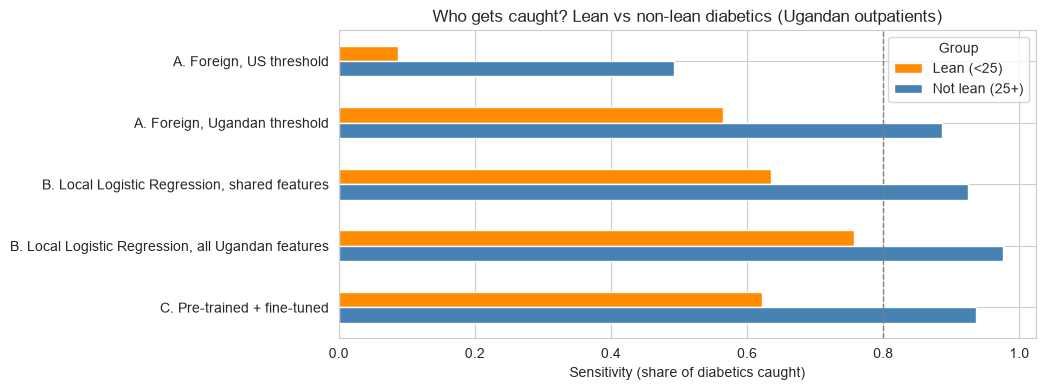

In [64]:
# Sensitivity for lean and non-lean diabetics under each approach (dashed line = 80% target)
plot_data = main["Sensitivity"].unstack().loc[list(approaches), ["Lean (<25)", "Not lean (25+)"]]
ax = plot_data.plot(kind="barh", figsize=(9, 4), color=["darkorange", "steelblue"])
ax.axvline(0.8, color="grey", linestyle="--", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Sensitivity (share of diabetics caught)")
ax.set_ylabel("")
ax.set_title("Who gets caught? Lean vs non-lean diabetics (Ugandan outpatients)")
plt.show()

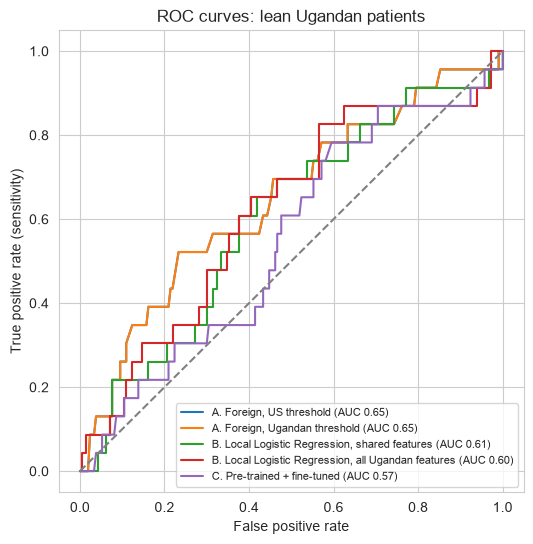

In [65]:
# ROC curves for lean patients (first cross-validation repeat for the cross-validated models)
lean = (kas["BMI"] < 25).to_numpy()
plt.figure(figsize=(6, 6))
for name, (res, summary) in approaches.items():
    fpr, tpr, _ = roc_curve(kas["Diabetes"][lean], res[0][0][lean])
    plt.plot(fpr, tpr, label=f"{name} (AUC {summary.loc['Lean (<25)', 'AUC']:.2f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curves: lean Ugandan patients")
plt.legend(fontsize=8)
plt.show()

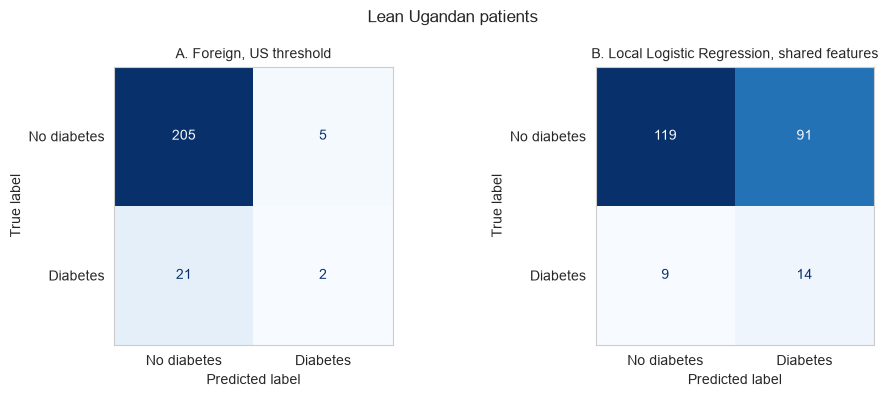

In [66]:
# Confusion matrices for lean patients: foreign model vs best local model (first repeat)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["A. Foreign, US threshold", f"B. Local {best_name}, shared features"]):
    preds = approaches[name][0][0][1]
    ConfusionMatrixDisplay.from_predictions(kas["Diabetes"][lean], preds[lean], ax=ax, cmap="Blues",
                                            display_labels=["No diabetes", "Diabetes"], colorbar=False)
    ax.set_title(name, fontsize=10)
    ax.grid(False)
plt.suptitle("Lean Ugandan patients")
plt.tight_layout()
plt.show()

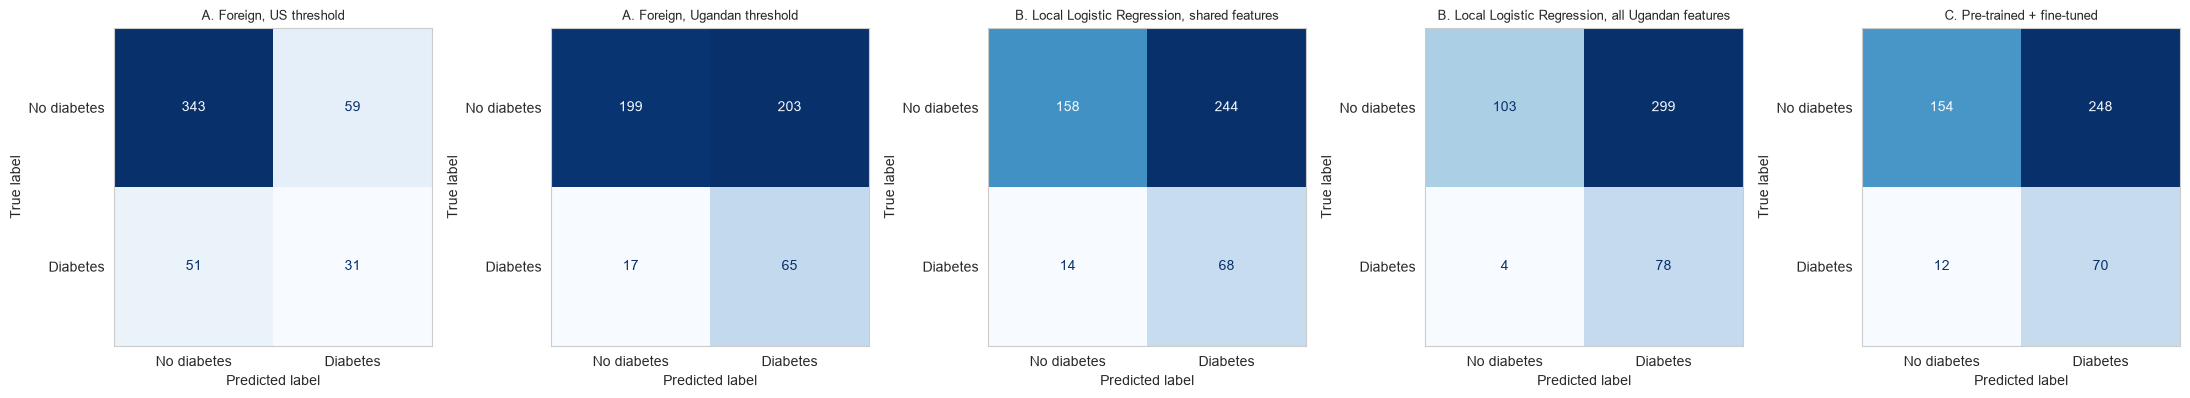

In [67]:
# Confusion matrices of each approach for all patients (first repeat for the cross-validated models)
fig, axes = plt.subplots(1, len(approaches), figsize=(22, 4))
for ax, (name, (res, summary)) in zip(axes, approaches.items()):
    ConfusionMatrixDisplay.from_predictions(kas["Diabetes"], res[0][1], ax=ax, cmap="Blues", colorbar=False,
                                            display_labels=["No diabetes", "Diabetes"])
    ax.set_title(name, fontsize=9)
    ax.grid(False)
plt.tight_layout()
plt.show()

### 10. Experiment D: testing on an independent Ugandan population (STEPS)

The models are now tested on the national STEPS survey, which none of them has seen. Each model keeps the threshold chosen on its own training data.

In [68]:
# Training the final local and fine-tuned models on all Kasujja patients, with thresholds from cross-validation
X_kas, y_kas = kas[shared_features], kas["Diabetes"]
final_models, thresholds = {}, {}
for name, model in {"Local": models[best_name], "Fine-tuned": fine_tuned}.items():
    final_models[name] = clone(model).fit(X_kas, y_kas)
    oof = cross_val_predict(clone(model), X_kas, y_kas, cv=5, method="predict_proba")[:, 1]
    thresholds[name] = choose_threshold(y_kas, oof)
final_models["Foreign, US threshold"], thresholds["Foreign, US threshold"] = us_model, us_threshold
final_models["Foreign, Ugandan threshold"] = us_model
thresholds["Foreign, Ugandan threshold"] = choose_threshold(y_kas, kas_probs_us)
thresholds

{'Local': np.float64(0.39),
 'Fine-tuned': np.float64(0.33),
 'Foreign, US threshold': np.float64(0.46),
 'Foreign, Ugandan threshold': np.float64(0.19)}

In [69]:
# Scoring each model on the STEPS national sample
steps_results = {}
for name in ["Foreign, US threshold", "Foreign, Ugandan threshold", "Local", "Fine-tuned"]:
    probs = final_models[name].predict_proba(steps[shared_features])[:, 1]
    steps_results[name] = summarise([(probs, (probs >= thresholds[name]).astype(int))], steps)
steps_table = pd.concat(steps_results)
steps_table.loc[(slice(None), ["All", "Lean (<25)", "Not lean (25+)"]),
                ["People", "Diabetics caught", "AUC", "Sensitivity", "Specificity", "Precision", "F1"]]

People Diabetics caught    AUC  \
                           Group                                            
Foreign, US threshold      All               3410         15 of 44  0.704   
                           Lean (<25)        2659          4 of 27  0.669   
                           Not lean (25+)     751         11 of 17  0.734   
Foreign, Ugandan threshold All               3410         24 of 44  0.704   
                           Lean (<25)        2659         11 of 27  0.669   
                           Not lean (25+)     751         13 of 17  0.734   
Local                      All               3410         28 of 44  0.713   
                           Lean (<25)        2659         11 of 27  0.651   
                           Not lean (25+)     751         17 of 17  0.789   
Fine-tuned                 All               3410         29 of 44  0.699   
                           Lean (<25)        2659         16 of 27  0.664   
                           Not lean (25+)     751         13 of 17  0.728   

                                           Sensitivity  Specificity  \
                           Group                                      
Foreign, US threshold      All                   0.341        0.915   
                           Lean (<25)            0.148        0.947   
                           Not lean (25+)        0.647        0.798   
Foreign, Ugandan threshold All                   0.545        0.700   
                           Lean (<25)            0.407        0.757   
                           Not lean (25+)        0.765        0.497   
Local                      All                   0.636        0.645   
                           Lean (<25)            0.407        0.725   
                           Not lean (25+)        1.000        0.358   
Fine-tuned                 All                   0.659        0.613   
                           Lean (<25)            0.593        0.647   
                           Not lean (25+)        0.765        0.493   

                                           Precision     F1  
                           Group                             
Foreign, US threshold      All                 0.050  0.087  
                           Lean (<25)          0.028  0.047  
                           Not lean (25+)      0.069  0.125  
Foreign, Ugandan threshold All                 0.023  0.045  
                           Lean (<25)          0.017  0.032  
                           Not lean (25+)      0.034  0.065  
Local                      All                 0.023  0.044  
                           Lean (<25)          0.015  0.029  
                           Not lean (25+)      0.035  0.067  
Fine-tuned                 All                 0.022  0.042  
                           Lean (<25)          0.017  0.033  
                           Not lean (25+)      0.034  0.065

### 11. Interpretation: what drives the US and Ugandan models? (SHAP)

 We compare the US model with an XGBoost model trained on the Ugandan outpatients.

In [70]:
# SHAP values for the US model and a Ugandan XGBoost model, explained on the Ugandan patients
ug_xgb = clone(models["XGBoost"]).fit(X_kas, y_kas)
shap_us = shap.TreeExplainer(us_model).shap_values(X_kas)
shap_ug = shap.TreeExplainer(ug_xgb).shap_values(X_kas)

importance = pd.DataFrame({"US model": np.abs(shap_us).mean(axis=0),
                           "Ugandan model": np.abs(shap_ug).mean(axis=0)}, index=shared_features)
importance = importance / importance.sum()          # share of total importance
importance.round(3)

,US model,Ugandan model
Age,0.253,0.379
Sex,0.051,0.089
BMI,0.295,0.354
HighBP,0.347,0.178
PhysActivity,0.055,0.000


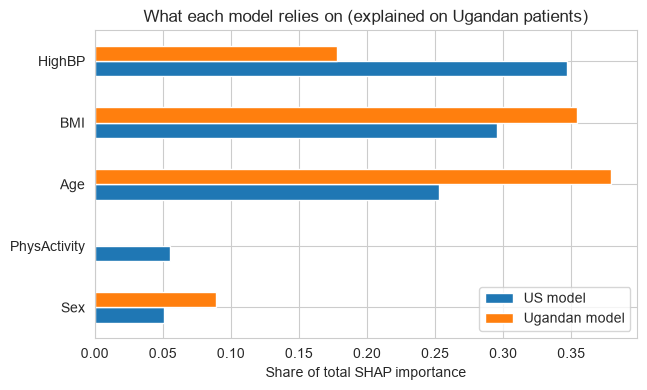

In [71]:
# Plotting the share of importance of each feature in each model
importance.sort_values("US model").plot(kind="barh", figsize=(7, 4))
plt.xlabel("Share of total SHAP importance")
plt.title("What each model relies on (explained on Ugandan patients)")
plt.show()

In [72]:
# For lean diabetics: the average push of each feature (negative = pushes towards "no diabetes")
lean_diabetic = ((kas["BMI"] < 25) & (kas["Diabetes"] == 1)).to_numpy()
pd.DataFrame({"US model": shap_us[lean_diabetic].mean(axis=0),
              "Ugandan model": shap_ug[lean_diabetic].mean(axis=0)}, index=shared_features).round(3)

,US model,Ugandan model
Age,-0.276,0.232
Sex,-0.039,0.021
BMI,-0.861,-0.313
HighBP,-0.022,0.047
PhysActivity,-0.119,0.000


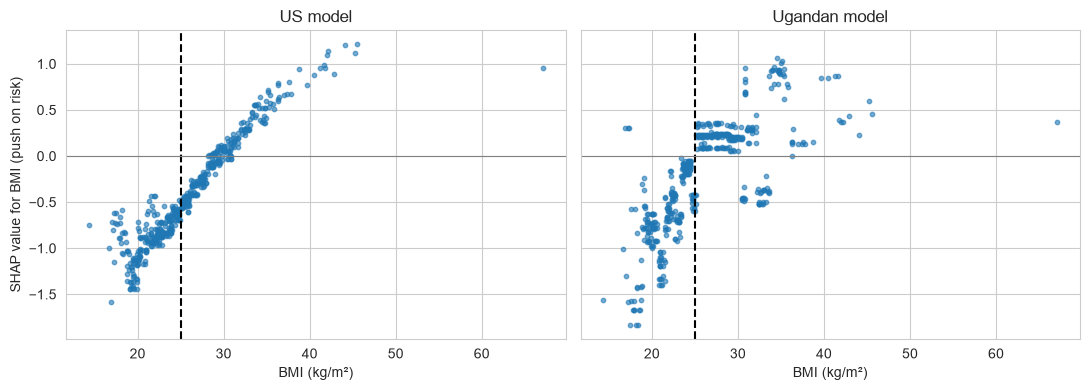

In [73]:
# SHAP dependence: how BMI changes the predicted risk in each model
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, values) in zip(axes, [("US model", shap_us), ("Ugandan model", shap_ug)]):
    ax.scatter(X_kas["BMI"], values[:, shared_features.index("BMI")], s=10, alpha=0.6)
    ax.axvline(25, color="black", linestyle="--")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel("BMI (kg/m²)")
    ax.set_title(name)
axes[0].set_ylabel("SHAP value for BMI (push on risk)")
plt.tight_layout()
plt.show()

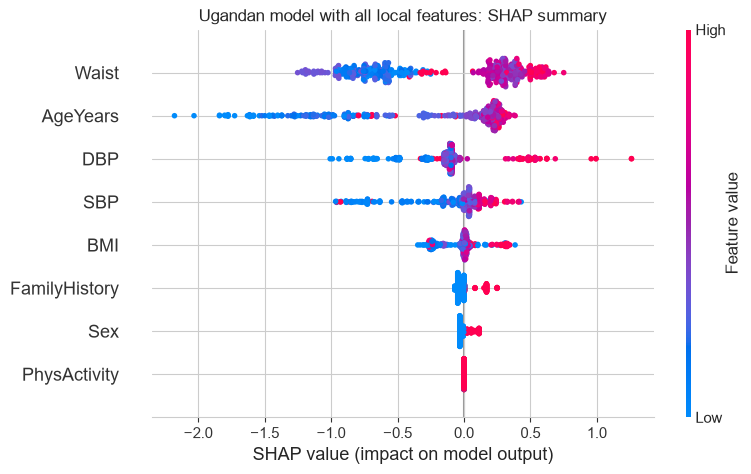

In [74]:
# SHAP summary for a Ugandan model with all local features
ug_full = clone(models["XGBoost"]).fit(kas[local_features], y_kas)
shap_full = shap.TreeExplainer(ug_full).shap_values(kas[local_features])
shap.summary_plot(shap_full, kas[local_features], show=False)
plt.title("Ugandan model with all local features: SHAP summary")
plt.show()

### Some key observations in (SHAP)

1. **The two models rely on different features:** the US model relies most on high blood pressure (35% of total importance) and BMI (30%); the Ugandan model relies most on **age (38%)** and BMI (35%), with high blood pressure much less important (18%).
2. **BMI pushes lean diabetics towards "no diabetes" much more strongly in the US model:** for lean Ugandan diabetics, the average SHAP value of BMI is **-0.86 in the US model** versus -0.31 in the Ugandan model. This is the mechanism behind the missed lean diabetics: the US model has learned that a normal BMI means low risk.
3. **Age works in opposite directions:** for lean Ugandan diabetics, age lowers the risk in the US model (-0.28) but raises it in the Ugandan model (+0.23), so the Ugandan model can still flag an older lean patient.
4. With all local features, waist circumference, age and blood pressure readings add information beyond BMI, which explains why the full Ugandan model catches more lean diabetics.

### 12. Screening a new patient

The final screening model is the best approach from the experiments: **Logistic Regression trained on the Ugandan outpatients with all local features**. Enter a person's details to get a result:
- **1 = positive:** higher risk, refer for a confirmatory blood test
- **0 = negative:** lower risk

The model score is a screening score, not a probability of having diabetes (class weights shift it upwards).

In [75]:
# Training the final screening model on all Ugandan outpatients, with its threshold from cross-validation
screening_model = clone(models[best_name]).fit(kas[local_features], kas["Diabetes"])
oof_scores = cross_val_predict(clone(models[best_name]), kas[local_features], kas["Diabetes"],
                               cv=5, method="predict_proba")[:, 1]
screening_threshold = choose_threshold(kas["Diabetes"], oof_scores)
print(f"Model: {best_name} with all local features | threshold: {screening_threshold}")

Model: Logistic Regression with all local features | threshold: 0.35


In [76]:
# Screening one person: returns 1 = positive (refer for a blood test) or 0 = negative
def screen_patient(age, sex, height_cm, weight_kg, waist_cm, sbp, dbp, family_history, physically_active):
    person = pd.DataFrame([{"AgeYears": age, "Sex": sex, "BMI": weight_kg / (height_cm / 100) ** 2,
                            "Waist": waist_cm, "SBP": sbp, "DBP": dbp,
                            "FamilyHistory": family_history, "PhysActivity": physically_active}])
    score = screening_model.predict_proba(person[local_features])[0, 1]
    result = int(score >= screening_threshold)
    print(f"BMI: {person['BMI'][0]:.1f} | model score: {score:.2f} (threshold {screening_threshold})")
    print(f"Result: {result} ->", "POSITIVE: refer for a confirmatory blood test" if result
          else "NEGATIVE: lower risk")
    return result

In [77]:
# Example: a lean 58-year-old woman with raised blood pressure and a family history of diabetes
screen_patient(age=58, sex=0, height_cm=160, weight_kg=58, waist_cm=84,
               sbp=145, dbp=92, family_history=1, physically_active=1)

BMI: 22.7 | model score: 0.58 (threshold 0.35)
Result: 1 -> POSITIVE: refer for a confirmatory blood test


1

In [ ]:
# Entering a person's details yourself: change the values below, then run this cell
# (sex: 1 = male, 0 = female; family history and physically active: 1 = yes, 0 = no)
screen_patient(age=45, sex=1, height_cm=170, weight_kg=62, waist_cm=82,
               sbp=130, dbp=85, family_history=0, physically_active=1)